# Modelado de PM2.5 — entrega final

## 1. Objetivo

Este notebook construye la tabla de predictores y evalúa los modelos de la entrega final. Responde las dos preguntas de investigación:

1. ¿Puede un modelo de Gradient Boosting, con ventanas de PM2.5 de los días previos y variables de calendario, predecir con un día de anticipación la media diaria de PM2.5 por estación con menor error que la persistencia y anticipar mejor los días en Nivel de Prevención?
2. ¿Cuánto mejora ese pronóstico al añadir la meteorología observada de SIATA, y qué variables explican sus predicciones según SHAP?

Esta primera versión cubre la tabla de predictores y el desempeño de la persistencia, la línea base que todo modelo debe superar. Requiere haber ejecutado los pasos de puesta en marcha del README (descargas y `scripts/build_meteo_hourly.py`).

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.ensemble import HistGradientBoostingRegressor

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.data import load_pm25_files
from src.data.stations import PM25_TO_METEO
from src.features import CALENDAR_FEATURES, METEO_FEATURES, PM25_FEATURES, TARGET, build_features
from src.models import (
    PREVENTION_THRESHOLD,
    regression_metrics,
    rolling_origin_predictions,
    threshold_for_budget,
    warning_metrics,
)

DATA_DIR = PROJECT_ROOT / 'data' / 'raw' / 'pm25'
METEO_HOURLY = PROJECT_ROOT / 'data' / 'interim' / 'meteo_hourly.csv'
TEST_YEARS = [2022, 2023, 2024, 2025]

/home/alejo/Documents/university/air-quality-applied-ml/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Carga

Se usan las mismas 16 estaciones y la misma ventana que en el EDA (2018–2025). La carga empieza el 25 de diciembre de 2017 solo para que los rezagos de los primeros días de 2018 tengan datos; esos días previos se descartan después. La meteorología es la tabla horaria construida por `scripts/build_meteo_hourly.py`, que ya descarta los minutos marcados como dudosos y exige 45 minutos válidos por hora.

In [2]:
LOAD_START, WINDOW_START, WINDOW_END = '2017-12-25', '2018-01-01', '2025-12-31'

pm25_wide = load_pm25_files(DATA_DIR)
pm25_wide = pm25_wide[pm25_wide['fecha_hora'].between(LOAD_START, f'{WINDOW_END} 23:00')]
pm25_hourly = pm25_wide.melt(
    id_vars='fecha_hora', value_vars=list(PM25_TO_METEO), var_name='station_id', value_name='pm25'
)
meteo_hourly = pd.read_csv(METEO_HOURLY, parse_dates=['fecha_hora'])

print('PM2.5 horario (estación-hora):', pm25_hourly.shape)
print('Meteorología horaria:', meteo_hourly.shape)
print('Horas con presión de 0 hPa:', int((meteo_hourly['pr'] == 0).sum()))

PM2.5 horario (estación-hora): (1124736, 3)
Meteorología horaria: (801839, 16)
Horas con presión de 0 hPa: 7


La bandera de calidad de SIATA no marca las 7 horas con presión de 0 hPa detectadas en el EDA. Una presión de 0 hPa no es física (en el valle ronda 840 hPa), así que `build_features` las trata como faltantes antes de calcular la media diaria. Era un pendiente abierto desde la Entrega 1.

## 3. Tabla de predictores

Cada fila es una **estación en un día `d`**. Todo predictor usa información observada hasta el final del día `d`; el target es la media del día `d + 1`. La construcción está en `src/features/build_features.py` y sus pruebas en `tests/test_build_features.py`, que incluyen una que verifica que cambiar cualquier dato del día `d + 1` solo cambia el target.

| Grupo | Predictores | Qué representan |
| --- | --- | --- |
| PM2.5 de hoy | `pm25_mean`, `pm25_max`, `pm25_evening_mean` | Media del día (≥18 h válidas), máximo horario y media de 18:00 a 23:00 (≥4 h), la parte del día más cercana a mañana. |
| Ventanas de tiempo | `pm25_lag1` … `pm25_lag6` | Media diaria de 1 a 6 días antes. Con `pm25_mean` cubren la última semana. |
| Ventanas móviles | `pm25_roll3_mean`, `pm25_roll7_mean`, `pm25_roll7_std`, `pm25_diff1` | Nivel y variabilidad de los últimos 3 y 7 días, y cambio respecto a ayer. |
| Meteorología del día | `t`, `h`, `pr`, `vv`, `vv_max`, `p`, `p_sum3` | Temperatura, humedad, presión y viento medios; ráfaga máxima; lluvia del día y de los últimos 3 días (entrada que usó Baena-Salazar et al.). |
| Calendario de mañana | `target_month`, `target_day_of_week` | Mes y día de la semana del día pronosticado, que se conocen de antemano. |

Las ventanas móviles admiten algunos días faltantes (2 de 3 y 5 de 7); los rezagos y la lluvia de 3 días no. No se imputa nada.

In [3]:
features = build_features(pm25_hourly, meteo_hourly, PM25_TO_METEO, LOAD_START, WINDOW_END)
features = features[features['date'] >= WINDOW_START].reset_index(drop=True)
supervised = features.dropna(subset=['pm25_mean', TARGET]).copy()
supervised['year'] = supervised['date'].dt.year
station_dummies = pd.get_dummies(supervised['station_id'], prefix='est', dtype=float)
supervised = pd.concat([supervised, station_dummies], axis=1)
STATION_FEATURES = list(station_dummies.columns)
supervised['inicio_episodio'] = (supervised['pm25_mean'] < PREVENTION_THRESHOLD) & (supervised[TARGET] >= PREVENTION_THRESHOLD)

print('Tabla estación-día:', features.shape)
print('Con media de hoy:', int(features['pm25_mean'].notna().sum()))
print('Tabla supervisada (media de hoy y target):', len(supervised))
display(supervised.head())

Tabla estación-día: (46752, 27)
Con media de hoy: 45152
Tabla supervisada (media de hoy y target): 44399


,station_id,date,codigo,valid_hours,pm25_mean,pm25_lag1,pm25_lag2,pm25_lag3,pm25_lag4,pm25_lag5,...,est_ITA-CJUS,est_ITA-CONC,est_MED-ALTA,est_MED-ARAN,est_MED-BEME,est_MED-SCRI,est_MED-TESO,est_MED-VILL,est_SAB-RAME,inicio_episodio
0,BAR-TORR,2018-01-01,82,23,17.831593,10.133717,11.499272,9.370924,12.287847,11.286822,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False
1,BAR-TORR,2018-01-02,82,23,13.014660,17.831593,10.133717,11.499272,9.370924,12.287847,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False
2,BAR-TORR,2018-01-03,82,23,12.264085,13.014660,17.831593,10.133717,11.499272,9.370924,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False
3,BAR-TORR,2018-01-04,82,24,10.933441,12.264085,13.014660,17.831593,10.133717,11.499272,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False
4,BAR-TORR,2018-01-05,82,24,16.933715,10.933441,12.264085,13.014660,17.831593,10.133717,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False


Las cifras coinciden con el EDA: 46.752 combinaciones estación-día, 45.152 con media diaria y 44.399 con media de hoy y target de mañana. La tabla de predictores no pierde ni añade registros respecto a la caracterización de la Entrega 1.

## 4. Faltantes por predictor

Gradient Boosting de scikit-learn en su versión `HistGradientBoostingRegressor` acepta valores faltantes: en cada división aprende hacia qué rama enviarlos. Por eso se conservan los registros con algún predictor vacío en vez de descartarlos o imputarlos.

In [4]:
missing = supervised[PM25_FEATURES + METEO_FEATURES + CALENDAR_FEATURES].isna().mean().mul(100).round(1)
display(missing.to_frame('faltante_pct').T)
complete_meteo = supervised[METEO_FEATURES].notna().all(axis=1)
print('Registros con toda la meteorología:', int(complete_meteo.sum()), f'({100 * complete_meteo.mean():.1f} %)')

,pm25_mean,pm25_lag1,pm25_lag2,pm25_lag3,pm25_lag4,pm25_lag5,pm25_lag6,pm25_roll3_mean,pm25_roll7_mean,pm25_roll7_std,...,pm25_evening_mean,t,h,pr,vv,vv_max,p,p_sum3,target_month,target_day_of_week
faltante_pct,0.0,1.6,2.3,2.6,2.9,3.0,3.0,0.7,1.5,1.5,...,0.7,7.6,8.2,17.4,10.9,11.3,9.2,11.0,0.0,0.0


Registros con toda la meteorología: 32455 (73.1 %)


Los predictores de PM2.5 tienen a lo sumo 3 % de faltantes: los rezagos solo se pierden cuando algún día previo no alcanzó 18 horas válidas. La meteorología tiene más huecos, sobre todo la presión (17,4 %), por la estación 252 sin presión desde 2019 (asignada a ITA-CJUS y ENV-HOSP). Solo el 73,1 % de los registros tiene toda la meteorología. Es algo menos que los 33.134 del EDA porque ahora se exige también la lluvia de los tres días previos y se descartan las presiones de 0 hPa. Excluir esos registros reduciría la tabla en una cuarta parte, por lo que el modelo los usará con faltantes.

## 5. Línea base: persistencia por año de prueba

La persistencia pronostica que mañana tendrá la misma media que hoy. Se evalúa en cada año de prueba del origen móvil (2022, 2023, 2024 y 2025, según el año del día `d`, como en la Tabla II del paper). Las métricas están en `src/models/evaluation.py`. Además del error se reporta R², porque es la métrica que publicaron Baena-Salazar et al., y el desempeño como aviso de Nivel de Prevención con umbral 38 µg/m³.

In [5]:
rows = []
for year in TEST_YEARS:
    test = supervised[supervised['year'] == year]
    warning = warning_metrics(test[TARGET], test['pm25_mean'], test['inicio_episodio'], PREVENTION_THRESHOLD)
    rows.append({
        'año': year,
        'registros': len(test),
        **regression_metrics(test[TARGET], test['pm25_mean']),
        **{k: warning[k] for k in ['eventos', 'avisos', 'precision', 'recall']},
    })
persistence = pd.DataFrame(rows).set_index('año')
display(persistence.round(3))

,registros,MAE,RMSE,R2,eventos,avisos,precision,recall
año,,,,,,,,
2022,5546,3.610,4.701,0.537,59,58,0.500,0.492
2023,5465,3.362,4.508,0.438,36,37,0.270,0.278
2024,5520,3.560,4.668,0.649,158,159,0.597,0.601
2025,5409,2.950,3.884,0.469,4,5,0.000,0.000


La persistencia comete un error medio de 2,95 a 3,61 µg/m³ según el año. Su R² va de 0,44 a 0,65, muy por debajo del 0,80 que alcanza en el periodo de validación de Baena-Salazar et al. (enero–marzo de 2016, ver `feedback-delivery-01/respuestas.md`). La razón es que el R² depende de cuánto varía la serie en el periodo evaluado: ese trimestre incluyó una contingencia ambiental con grandes cambios de nivel, mientras que un año completo contiene muchos días de concentración moderada. Por eso la comparación con ese estudio debe hacerse en su mismo periodo y no con el R² de nuestra ventana.

Como aviso de Nivel de Prevención, la persistencia acierta alrededor de la mitad de los eventos en 2022 y 2024, años con episodios de varios días, y apenas una cuarta parte en 2023, cuando la mayoría de los eventos son inicios de episodio (26 de 36). En 2025, con solo 4 eventos, no acierta ninguno: no hay suficientes eventos para medir anticipación, lo que confirma que la evaluación debe reportarse año por año y no con un único periodo de prueba.

## 6. Protocolo de evaluación

Se comparan tres pronósticos de la media de mañana:

| Pronóstico | Predictores |
| --- | --- |
| Persistencia | La media de hoy. |
| Gradient Boosting sin meteorología | Estación, PM2.5 (hoy, ventanas y rezagos) y calendario. Responde la pregunta 1. |
| Gradient Boosting con meteorología | Lo anterior más la meteorología del día. La diferencia con el anterior responde la pregunta 2. |

**Origen móvil.** Cada año de 2019 a 2025 se predice con un modelo entrenado solo con los años anteriores (2019 con 2018; 2025 con 2018–2024). Los años 2022 a 2025 son los de prueba; las predicciones de 2019–2021 sirven solo para elegir hiperparámetros y calibrar avisos, sin mirar ningún año de prueba.

**Hiperparámetros.** Se eligieron con el MAE fuera de muestra de 2019–2021. El MAE casi no cambió entre configuraciones (diferencias de centésimas de µg/m³) y las mejores fueron modelos pequeños: árboles de 7 hojas, tasa de aprendizaje 0,03 y 300 iteraciones. Se usa la misma configuración en los dos modelos para que solo cambien los predictores. La estación entra como 16 columnas indicadoras (one-hot). Se descartó la variable categórica nativa de `HistGradientBoostingRegressor` porque `shap.TreeExplainer` no reproduce sus divisiones categóricas: la suma de los valores SHAP difería de la predicción en 0,61 µg/m³ en promedio. Con one-hot la suma es exacta y el MAE cambia en una centésima.

In [6]:
GB_PARAMS = dict(learning_rate=0.03, max_iter=300, max_leaf_nodes=7, min_samples_leaf=50, random_state=0)
FEATURES_SIN_METEO = [*STATION_FEATURES, *PM25_FEATURES, *CALENDAR_FEATURES]
FEATURES_CON_METEO = [*FEATURES_SIN_METEO, *METEO_FEATURES]
PREDICTED_YEARS = range(2019, 2026)


def gradient_boosting(columns):
    def fit_predict(train, test):
        model = HistGradientBoostingRegressor(**GB_PARAMS).fit(train[columns], train[TARGET])
        return model.predict(test[columns])
    return fit_predict


evaluated = supervised[supervised['year'] >= PREDICTED_YEARS[0]]
predictions = pd.DataFrame({
    'persistencia': evaluated['pm25_mean'],
    'GB sin meteo': rolling_origin_predictions(supervised, PREDICTED_YEARS, gradient_boosting(FEATURES_SIN_METEO)),
    'GB con meteo': rolling_origin_predictions(supervised, PREDICTED_YEARS, gradient_boosting(FEATURES_CON_METEO)),
})
MODELS = list(predictions)
print('Predicciones fuera de muestra:', predictions.shape)

Predicciones fuera de muestra: (38922, 3)


## 7. Error de concentración

modelo,persistencia,GB sin meteo,GB con meteo
año,,,
2022,3.610,3.000,2.958
2023,3.362,2.782,2.760
2024,3.560,2.854,2.831
2025,2.950,2.427,2.405
2022–2025,3.373,2.768,2.740


modelo,persistencia,GB sin meteo,GB con meteo
año,,,
2022,0.537,0.679,0.689
2023,0.438,0.618,0.622
2024,0.649,0.770,0.774
2025,0.469,0.653,0.662
2022–2025,0.563,0.706,0.713


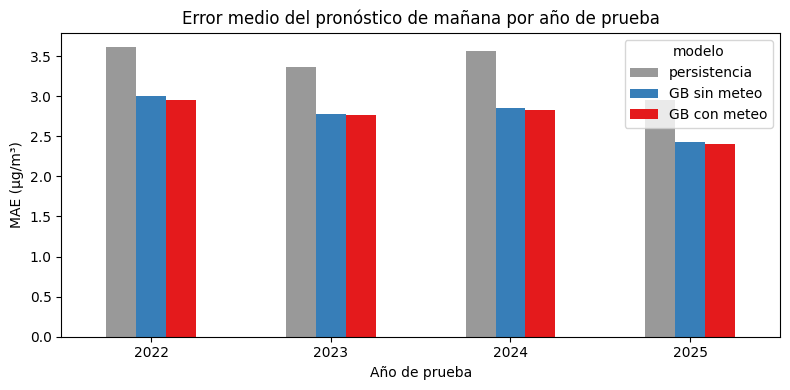

In [7]:
rows = []
for year in [*TEST_YEARS, '2022–2025']:
    mask = evaluated['year'] >= 2022 if year == '2022–2025' else evaluated['year'] == year
    for model in MODELS:
        rows.append({'año': year, 'modelo': model, **regression_metrics(evaluated.loc[mask, TARGET], predictions.loc[mask, model])})
regression = pd.DataFrame(rows).set_index(['año', 'modelo'])
display(regression['MAE'].unstack('modelo')[MODELS].round(3))
display(regression['R2'].unstack('modelo')[MODELS].round(3))

ax = regression['MAE'].unstack('modelo')[MODELS].loc[TEST_YEARS].plot.bar(figsize=(8, 4), rot=0, color=['#999999', '#377eb8', '#e41a1c'])
ax.set(xlabel='Año de prueba', ylabel='MAE (µg/m³)', title='Error medio del pronóstico de mañana por año de prueba')
plt.tight_layout()
plt.show()

Gradient Boosting reduce el error de la persistencia en los cuatro años de prueba. En 2022–2025 el MAE baja de 3,37 a 2,77 µg/m³ sin meteorología (−18 %) y a 2,74 µg/m³ con meteorología. El R² sube de 0,56 a 0,71. La meteorología mejora el MAE en los cuatro años, pero poco: entre 0,02 y 0,04 µg/m³, alrededor de 1 %, como anticipó la prueba lineal de la Entrega 1.

### 7.1 ¿Las diferencias son reales?

Las diferencias de MAE se estiman con un bootstrap por bloques: se remuestrean bloques de 14 días consecutivos (con todas las estaciones de esos días), para respetar que los errores de días cercanos y de estaciones vecinas están correlacionados. Se reporta el intervalo del 95 % de la diferencia en 2022–2025.

In [8]:
test = evaluated['year'] >= 2022
abs_error = predictions[test].sub(evaluated.loc[test, TARGET], axis=0).abs()
differences = pd.DataFrame({
    'GB sin meteo − persistencia': abs_error['GB sin meteo'] - abs_error['persistencia'],
    'GB con meteo − GB sin meteo': abs_error['GB con meteo'] - abs_error['GB sin meteo'],
})
block = (evaluated.loc[test, 'date'] - evaluated.loc[test, 'date'].min()).dt.days // 14
block_sums, block_counts = differences.groupby(block.to_numpy()).sum(), differences.groupby(block.to_numpy()).count()

rng = np.random.default_rng(0)
draws = []
for _ in range(5000):
    sample = rng.integers(0, len(block_sums), len(block_sums))
    draws.append(block_sums.iloc[sample].sum() / block_counts.iloc[sample].sum())
draws = pd.DataFrame(draws)
display(pd.DataFrame({
    'diferencia_MAE': differences.mean(),
    'IC95_inferior': draws.quantile(0.025),
    'IC95_superior': draws.quantile(0.975),
}).round(3))

by_station = abs_error.groupby(evaluated.loc[test, 'station_id']).mean()
gain = (by_station['GB sin meteo'] - by_station['GB con meteo']).sort_values()
print('Estaciones donde la meteorología reduce el MAE:', int((gain > 0).sum()), 'de', len(gain))
display(gain.round(3).to_frame('reducción_MAE_por_meteo'))

,diferencia_MAE,IC95_inferior,IC95_superior
GB sin meteo − persistencia,-0.606,-0.679,-0.532
GB con meteo − GB sin meteo,-0.027,-0.047,-0.011


Estaciones donde la meteorología reduce el MAE: 14 de 16


,reducción_MAE_por_meteo
station_id,
BEL-FEVE,-0.030
ITA-CONC,-0.007
CEN-TRAF,0.002
BAR-TORR,0.008
MED-SCRI,0.009
MED-TESO,0.014
EST-HOSP,0.015
COP-CVID,0.018
CAL-JOAR,0.033


Las dos mejoras son reales. Gradient Boosting reduce el MAE de la persistencia en 0,61 µg/m³ (IC 95 %: 0,53 a 0,68). La meteorología lo reduce en 0,027 µg/m³ (IC 95 %: 0,011 a 0,047): es pequeña, pero ningún intervalo incluye el cero, y la mejora aparece en 14 de las 16 estaciones.

La ganancia por estación coincide con la calidad de la meteorología asignada. Las dos estaciones donde la meteorología empeora levemente el error son BEL-FEVE (su estación 271 no tiene datos desde agosto de 2024) e ITA-CONC (la 206 no midió viento entre 2019 y 2024). La mayor ganancia está en MED-BEME, ITA-CJUS y MED-ALTA. Esto sugiere que cubrir esos huecos podría aumentar algo el aporte.

## 8. Avisos de Nivel de Prevención

Un pronóstico se convierte en aviso cuando alcanza un umbral. Primero se usa el umbral fijo de 38 µg/m³. Una regresión que minimiza el error medio subestima los picos, así que con ese umbral avisa menos que la persistencia y la comparación queda sesgada a favor de esta (decisión del 2026-09-14 en `docs/decisions.md`).

In [9]:
rows = []
for year in [*TEST_YEARS, '2022–2025']:
    mask = evaluated['year'] >= 2022 if year == '2022–2025' else evaluated['year'] == year
    for model in MODELS:
        rows.append({'año': year, 'modelo': model, **warning_metrics(
            evaluated.loc[mask, TARGET], predictions.loc[mask, model], evaluated.loc[mask, 'inicio_episodio'], PREVENTION_THRESHOLD)})
fixed = pd.DataFrame(rows).set_index(['año', 'modelo'])
display(fixed.loc['2022–2025'].round(3))

,eventos,avisos,precision,recall,inicios,inicios_avisados
modelo,,,,,,
persistencia,257,259,0.517,0.521,123,0
GB sin meteo,257,157,0.631,0.385,123,12
GB con meteo,257,167,0.629,0.409,123,14


Con el umbral fijo de 38 µg/m³, Gradient Boosting avisa mucho menos que la persistencia (157–167 avisos frente a 259 en 2022–2025). Es más preciso (0,63 frente a 0,52), pero detecta menos eventos (recall de 0,39–0,41 frente a 0,52). Aun así anticipa 12–14 inicios de episodio, que la persistencia con ese umbral nunca puede anticipar. Como cada método avisa un número distinto de veces, esta tabla no permite decir cuál es mejor.

### 8.1 Comparación a igual número de avisos

Para comparar con justicia, cada método recibe el mismo presupuesto de avisos: su umbral se fija de modo que, en los años anteriores al de prueba, emita tantos avisos como eventos hubo. El umbral se calcula solo con predicciones fuera de muestra de esos años y se congela antes de mirar el año de prueba. Para la persistencia ese umbral resulta prácticamente 38 µg/m³.

In [10]:
rows = []
for year in TEST_YEARS:
    calibration, mask = evaluated['year'] < year, evaluated['year'] == year
    for model in MODELS:
        threshold = threshold_for_budget(evaluated.loc[calibration, TARGET], predictions.loc[calibration, model])
        rows.append({'año': year, 'modelo': model, 'umbral': threshold, **warning_metrics(
            evaluated.loc[mask, TARGET], predictions.loc[mask, model], evaluated.loc[mask, 'inicio_episodio'], threshold)})
budget = pd.DataFrame(rows).set_index(['año', 'modelo'])
display(budget.round(3))

totals = budget.groupby('modelo')[['eventos', 'avisos', 'inicios', 'inicios_avisados']].sum().loc[MODELS]
hits = (budget['precision'] * budget['avisos']).groupby('modelo').sum().loc[MODELS]
totals['precision'] = hits / totals['avisos']
totals['recall'] = hits / totals['eventos']
totals['recall_inicios'] = totals['inicios_avisados'] / totals['inicios']
display(totals.round(3))

umbral  eventos  avisos  precision  recall  inicios  \
año  modelo                                                              
2022 persistencia  37.991       59      58      0.500   0.492       30   
     GB sin meteo  35.213       59      73      0.438   0.542       30   
     GB con meteo  35.247       59      61      0.508   0.525       30   
2023 persistencia  37.980       36      37      0.270   0.278       26   
     GB sin meteo  35.362       36      34      0.353   0.333       26   
     GB con meteo  35.256       36      34      0.324   0.306       26   
2024 persistencia  37.991      158     159      0.597   0.601       63   
     GB sin meteo  35.332      158     151      0.596   0.570       63   
     GB con meteo  35.247      158     180      0.544   0.620       63   
2025 persistencia  37.995        4       5      0.000   0.000        4   
     GB sin meteo  35.283        4      17      0.059   0.250        4   
     GB con meteo  35.410        4      13      0.000   0.000        4   

                   inicios_avisados  
año  modelo                          
2022 persistencia                 0  
     GB sin meteo                10  
     GB con meteo                 7  
2023 persistencia                 0  
     GB sin meteo                 3  
     GB con meteo                 3  
2024 persistencia                 0  
     GB sin meteo                15  
     GB con meteo                20  
2025 persistencia                 0  
     GB sin meteo                 1  
     GB con meteo                 0

,eventos,avisos,inicios,inicios_avisados,precision,recall,recall_inicios
modelo,,,,,,,
persistencia,257,259,123,0,0.517,0.521,0.000
GB sin meteo,257,275,123,29,0.491,0.525,0.236
GB con meteo,257,288,123,30,0.486,0.545,0.244


Con un presupuesto de avisos comparable, Gradient Boosting usa un umbral de unos 35 µg/m³. En 2022–2025 detecta tantos eventos como la persistencia (recall de 0,53–0,55 frente a 0,52), con una precisión algo menor (0,49 frente a 0,52) porque emitió entre 6 % y 11 % más avisos: el presupuesto se calibra con años anteriores y la frecuencia de eventos cambia de un año a otro. La diferencia está en qué eventos detecta. Gradient Boosting anticipa 29–30 de los 123 inicios de episodio (24 %); la persistencia no anticipa ninguno, porque sus avisos siempre caen en días que ya estaban en prevención.

Por año, el resultado depende de cuántos eventos haya. En 2023, el año con más inicios en proporción, Gradient Boosting sin meteorología supera a la persistencia en precisión y en recall. En 2025, con 4 eventos, ningún método funciona. La meteorología apenas cambia la detección de inicios a igual presupuesto (30 frente a 29), así que su aporte se ve en el error y no en los avisos.

## 9. Error en los días que importan

In [11]:
event_days = evaluated.loc[test, TARGET] >= PREVENTION_THRESHOLD
start_days = evaluated.loc[test, 'inicio_episodio']
display(pd.DataFrame({
    'todos los días': abs_error.mean(),
    'días en prevención': abs_error[event_days].mean(),
    'inicios de episodio': abs_error[start_days].mean(),
    'sesgo en días en prevención': predictions.loc[test][event_days].sub(evaluated.loc[test, TARGET][event_days], axis=0).mean(),
}).loc[MODELS].round(2))

,todos los días,días en prevención,inicios de episodio,sesgo en días en prevención
persistencia,3.37,5.88,8.40,-4.11
GB sin meteo,2.77,6.90,9.02,-6.05
GB con meteo,2.74,6.56,8.79,-5.46


En promedio Gradient Boosting es mejor, pero en los días en prevención se equivoca más que la persistencia (6,90 frente a 5,88 µg/m³). La causa es que subestima los picos: en esos días predice, en promedio, 6 µg/m³ menos de lo observado. Es lo esperable en un modelo que minimiza el error medio en una serie donde solo el 2,5 % de los días está en prevención, y por eso el aviso necesita un umbral menor que 38.

La meteorología ayuda más justo donde importa. En los días en prevención reduce el MAE de 6,90 a 6,56 µg/m³ y el sesgo de −6,05 a −5,46: una mejora de 0,34 µg/m³, más de diez veces la del promedio general (0,03). En los inicios de episodio ningún modelo mejora el error de la persistencia; lo que sí logra Gradient Boosting es ordenarlos mejor, y por eso los avisa.

## 11. ¿Qué variables explican el pronóstico? (SHAP)

SHAP reparte cada predicción entre las variables de entrada: el valor SHAP de una variable es cuánto empuja la predicción por encima o por debajo del promedio. La importancia de una variable es la media del valor absoluto de su SHAP, y aquí se expresa como porcentaje del total.

Cada año de prueba se explica con el mismo modelo que lo predijo (entrenado con los años anteriores), y se juntan los cuatro años. Las 16 columnas de estación se suman en una sola variable `estación`. Se analiza el modelo con meteorología, que usa todas las variables.

In [12]:
shap_frames = []
for year in TEST_YEARS:
    train, test_year = supervised[supervised['year'] < year], supervised[supervised['year'] == year]
    model = HistGradientBoostingRegressor(**GB_PARAMS).fit(train[FEATURES_CON_METEO], train[TARGET])
    explainer = shap.TreeExplainer(model)
    values = explainer.shap_values(test_year[FEATURES_CON_METEO])
    gap = np.abs(values.sum(axis=1) + explainer.expected_value - model.predict(test_year[FEATURES_CON_METEO])).max()
    assert gap < 1e-6, f'SHAP no reproduce la predicción en {year}: {gap}'
    shap_frames.append(pd.DataFrame(values, columns=FEATURES_CON_METEO, index=test_year.index))
shap_values = pd.concat(shap_frames)
shap_values['estación'] = shap_values[STATION_FEATURES].sum(axis=1)
shap_values = shap_values.drop(columns=STATION_FEATURES)

importance = shap_values.abs().mean()
importance_pct = (100 * importance / importance.sum()).sort_values(ascending=False)
display(importance_pct.round(1).to_frame('importancia_pct'))

GROUPS = {
    'PM2.5 de hoy': ['pm25_mean', 'pm25_max', 'pm25_evening_mean'],
    'Rezagos y ventanas': [c for c in PM25_FEATURES if c not in ('pm25_mean', 'pm25_max', 'pm25_evening_mean')],
    'Meteorología': METEO_FEATURES,
    'Calendario': CALENDAR_FEATURES,
    'Estación': ['estación'],
}
display(pd.Series({group: importance_pct[columns].sum() for group, columns in GROUPS.items()}).round(1).to_frame('importancia_pct'))

,importancia_pct
pm25_evening_mean,24.6
pm25_mean,24.3
pm25_roll7_mean,13.5
target_day_of_week,10.3
target_month,7.9
estación,3.9
p,3.7
pr,3.0
pm25_lag6,2.1
pm25_lag1,1.4


,importancia_pct
PM2.5 de hoy,49.5
Rezagos y ventanas,19.9
Meteorología,8.6
Calendario,18.2
Estación,3.9


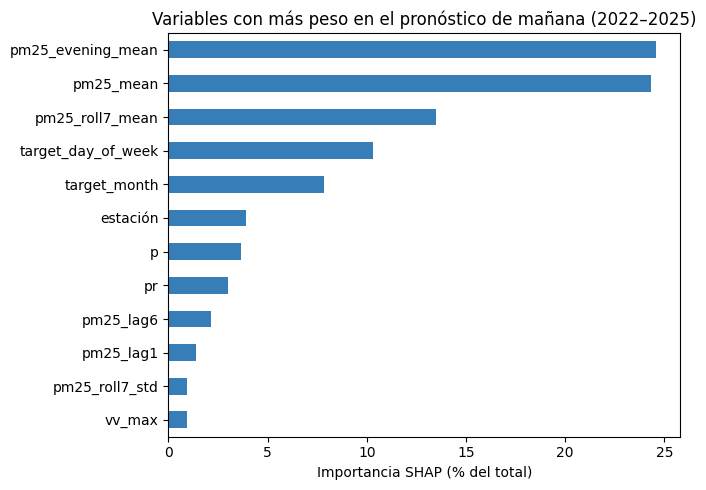

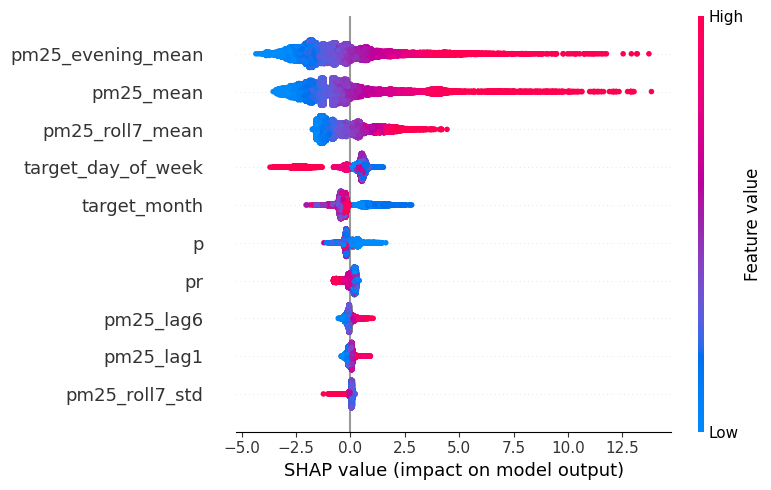

In [13]:
top = importance_pct.index[:12][::-1]
ax = importance_pct[top].plot.barh(figsize=(7, 5), color='#377eb8')
ax.set(xlabel='Importancia SHAP (% del total)', ylabel='', title='Variables con más peso en el pronóstico de mañana (2022–2025)')
plt.tight_layout()
plt.show()

# Dirección del efecto: cada punto es un registro estación-día; el color es el valor de la variable.
# La estación se omite porque no tiene un único valor numérico.
beeswarm = [c for c in importance_pct.index if c != 'estación'][:10]
shap.summary_plot(
    shap_values[beeswarm].to_numpy(),
    supervised.loc[shap_values.index, beeswarm],
    feature_names=beeswarm,
    show=False,
    plot_size=(8, 5),
)
plt.tight_layout()
plt.show()

**Sí: lo que más pesa es el PM2.5 del día anterior al pronosticado**, igual que en Baena-Salazar et al. Las variables del día `d` (media, media de 18:00 a 23:00 y máximo) suman el 49,5 % de la importancia. Entre ellas, las últimas horas del día (24,6 %) pesan tanto como la media completa (24,3 %), lo cual es razonable porque son las más cercanas a mañana.

Después vienen:

- **Rezagos y ventanas (19,9 %).** Casi todo corresponde a la media de siete días (13,5 %). Los rezagos sueltos de 1 a 5 días pesan poco porque su información ya está en las medias móviles. La excepción es el rezago de 6 días (2,1 %): el día `d − 6` es el mismo día de la semana que el día pronosticado, así que captura el ciclo semanal.
- **Calendario (18,2 %).** El día de la semana del día pronosticado baja la predicción los domingos (en 2024, 2,2 µg/m³ en promedio y hasta 4), cuando hay menos tráfico. El mes la sube de enero a marzo, con el máximo en marzo.
- **Meteorología (8,6 %).** Sobre todo la lluvia del día (3,7 %) y la presión (3,0 %): más lluvia y más presión bajan la predicción, el mismo signo que mostraron las correlaciones del EDA. La presión también varía con la altitud de cada estación, así que parte de su efecto puede ser un efecto de ubicación.
- **Estación (3,9 %).**

El 8,6 % de la meteorología es coherente con su aporte pequeño al error medio: el modelo la usa, pero casi toda la información para el día siguiente ya está en el propio PM2.5.

### 11.1 Comparación con los pesos de Baena-Salazar et al.

En el modelo completo el crédito del PM2.5 se reparte entre variables muy parecidas (la media de hoy, la de la noche, la media de siete días), así que ninguna recibe por sí sola el peso que reporta Baena-Salazar et al. Para una comparación más cercana se entrena un segundo modelo solo con las entradas de su red que existen en nuestros datos: PM2.5 de hoy y de los dos días previos, temperatura, humedad, viento, lluvia del día y lluvia de tres días. No están la radiación ni la altura de la capa de mezcla.

SHAP y los pesos de una red neuronal son métodos distintos de medir importancia; se comparan el orden y la magnitud, no el número exacto.

In [14]:
BAENA_FEATURES = ['pm25_mean', 'pm25_lag1', 'pm25_lag2', 't', 'h', 'vv', 'p', 'p_sum3']
baena_frames, baena_predictions = [], []
for year in TEST_YEARS:
    train, test_year = supervised[supervised['year'] < year], supervised[supervised['year'] == year]
    model = HistGradientBoostingRegressor(**GB_PARAMS).fit(train[BAENA_FEATURES], train[TARGET])
    baena_frames.append(pd.DataFrame(shap.TreeExplainer(model).shap_values(test_year[BAENA_FEATURES]), columns=BAENA_FEATURES, index=test_year.index))
    baena_predictions.append(pd.Series(model.predict(test_year[BAENA_FEATURES]), index=test_year.index))
baena_shap = pd.concat(baena_frames)
baena_pred = pd.concat(baena_predictions)
baena_importance = 100 * baena_shap.abs().mean() / baena_shap.abs().mean().sum()
display(baena_importance.sort_values(ascending=False).round(1).to_frame('importancia_pct'))
print('MAE 2022–2025 del modelo con entradas tipo Baena-Salazar:', round(regression_metrics(evaluated.loc[baena_pred.index, TARGET], baena_pred)['MAE'], 3), 'µg/m³')

,importancia_pct
pm25_mean,65.7
pm25_lag2,11.8
pm25_lag1,7.5
p,6.6
h,4.2
t,1.9
vv,1.3
p_sum3,1.0


MAE 2022–2025 del modelo con entradas tipo Baena-Salazar: 3.117 µg/m³


Con entradas parecidas a las de Baena-Salazar et al., el PM2.5 de hoy concentra el 65,7 % de la importancia y los dos días previos otro 19,3 %. La meteorología suma el 15 %, encabezada por la lluvia (6,6 %) y la humedad (4,2 %). Su red asignó el 34,2 % al PM2.5 del día anterior. El orden coincide: es la entrada dominante en ambos estudios. La diferencia de magnitud se explica en parte porque su red incluía la altura de la capa de mezcla y la radiación, que aquí no están, y porque los dos métodos miden la importancia de forma distinta.

Este modelo reducido tiene un MAE de 3,12 µg/m³ en 2022–2025: mejor que la persistencia (3,37), pero bastante peor que el modelo completo (2,74). Las ventanas de tiempo (sobre todo la media de siete días y las últimas horas del día) y el calendario, que la red de Baena-Salazar no usaba, explican la mayor parte de esa diferencia.

## 12. Réplica del periodo de validación de Baena-Salazar et al.

Baena-Salazar et al. validaron su red neuronal con los primeros 91 días de 2016 (1 de enero a 31 de marzo), entrenando con datos desde enero de 2013. Aquí se repite ese diseño con las dos estaciones de su estudio que siguen en el histórico de PM2.5 (ITA-CONC y MED-UNNV; MED-MANT no aparece) y con la meteorología instalada en el mismo sitio antes de 2013: la 206 a 0,09 km de ITA-CONC y la 203 a 0,32 km de MED-UNNV (`BAENA_PM25_TO_METEO` en `src/data/stations.py`). Los archivos meteorológicos de 2013-01 a 2016-03 se descargan con:

```bash
python scripts/download_meteo_dataset.py --stations 203,206 --start 2013-01 --end 2016-03 --skip-network
```

Los predictores son los mismos que en el resto del notebook y los hiperparámetros también: no se ajusta nada con el periodo de prueba. El r² que publicaron proviene de gráficos de dispersión entre valores reales y pronosticados, así que se reporta como correlación al cuadrado (`r2_corr`), junto con el R² de la sección 7. Su "error" porcentual no está definido en el artículo y se compara con el MAPE.

In [15]:
import re

from src.data.load_meteo import load_meteo_station
from src.data.stations import BAENA_END, BAENA_PM25_TO_METEO, BAENA_START

BAENA_TEST = ('2016-01-01', '2016-03-31')
BAENA_REPORTED = pd.DataFrame(
    {'r2_corr': [0.806, 0.864], 'MAPE': [18.52, 12.35]}, index=['ITA-CONC', 'MED-UNNV']
)


def months_between(folder, start, end):
    month = lambda f: '-'.join(re.search(r'_(\d{4})_(\d{2})\.', f.name).groups())
    return [f for f in sorted(folder.glob('*.tab')) if start <= month(f) <= end]


pm25_2013 = load_pm25_files(DATA_DIR)
pm25_2013 = pm25_2013[pm25_2013['fecha_hora'] < '2016-04-01'].melt(
    id_vars='fecha_hora', value_vars=list(BAENA_PM25_TO_METEO), var_name='station_id', value_name='pm25'
)
meteo_2013 = pd.concat(
    [load_meteo_station(months_between(PROJECT_ROOT / 'data' / 'raw' / 'meteo' / str(code), BAENA_START, BAENA_END))
     for code in BAENA_PM25_TO_METEO.values()],
    ignore_index=True,
)
hours_2013 = len(pd.date_range('2013-01-01', '2016-03-31 23:00', freq='h'))
display(meteo_2013.groupby('codigo')[['t', 'h', 'pr', 'vv', 'p']].count().div(hours_2013).mul(100).round(1))

baena = build_features(pm25_2013, meteo_2013, BAENA_PM25_TO_METEO, '2013-01-01', '2016-03-31')
baena = baena.dropna(subset=['pm25_mean', TARGET]).copy()
baena['target_date'] = baena['date'] + pd.Timedelta(days=1)
baena_stations = pd.get_dummies(baena['station_id'], prefix='est', dtype=float)
baena = pd.concat([baena, baena_stations], axis=1)
baena_train = baena[baena['target_date'] < BAENA_TEST[0]]
baena_test = baena[baena['target_date'].between(*BAENA_TEST)]
print('Entrenamiento:', len(baena_train), '| prueba:', len(baena_test), baena_test.groupby('station_id').size().to_dict())
display(pd.DataFrame({'entrenamiento': baena_train[TARGET].describe(), 'prueba': baena_test[TARGET].describe()}).round(1))

,t,h,pr,vv,p
codigo,,,,,
203,94.3,94.4,94.4,94.3,94.1
206,92.1,92.1,92.1,92.1,92.1


Entrenamiento: 2027 | prueba: 175 {'ITA-CONC': 89, 'MED-UNNV': 86}


,entrenamiento,prueba
count,2027.0,175.0
mean,27.5,43.7
std,8.9,19.0
min,5.5,16.0
25%,21.2,29.2
50%,26.5,38.2
75%,32.4,51.5
max,69.4,103.2


Las dos estaciones meteorológicas tienen entre 92 % y 94 % de horas válidas en 2013–2016, y la tabla reproduce los mismos 89 y 86 días de prueba usados en la comparación de persistencia de `feedback-delivery-01/respuestas.md`. El periodo de prueba es muy distinto del de entrenamiento: su media (43,7 µg/m³) supera en 16 µg/m³ la de 2013–2015, y su máximo (103,2) supera en 34 µg/m³ el mayor valor de entrenamiento (69,4). Ese trimestre incluyó la contingencia ambiental de marzo–abril de 2016 que mencionan Baena-Salazar et al.

In [16]:
baena_columns = {
    'sin meteo': [*baena_stations.columns, *PM25_FEATURES, *CALENDAR_FEATURES],
    'con meteo': [*baena_stations.columns, *PM25_FEATURES, *CALENDAR_FEATURES, *METEO_FEATURES],
}
replica = {'persistencia': baena_test['pm25_mean']}
for label, columns in baena_columns.items():
    level = HistGradientBoostingRegressor(**GB_PARAMS).fit(baena_train[columns], baena_train[TARGET])
    replica[f'GB {label}'] = pd.Series(level.predict(baena_test[columns]), index=baena_test.index)
    change = HistGradientBoostingRegressor(**GB_PARAMS).fit(
        baena_train[columns], baena_train[TARGET] - baena_train['pm25_mean'])
    replica[f'GB {label} (cambio)'] = baena_test['pm25_mean'] + change.predict(baena_test[columns])


def replica_metrics(y_true, y_pred):
    return {
        **regression_metrics(y_true, y_pred),
        'r2_corr': np.corrcoef(y_true, y_pred)[0, 1] ** 2,
        'MAPE': 100 * ((y_true - y_pred).abs() / y_true).mean(),
    }


rows = []
for station in BAENA_PM25_TO_METEO:
    mask = baena_test['station_id'] == station
    rows.append({'estación': station, 'modelo': 'Baena-Salazar et al. (publicado)', **BAENA_REPORTED.loc[station].to_dict()})
    for model, values in replica.items():
        rows.append({'estación': station, 'modelo': model, **replica_metrics(baena_test.loc[mask, TARGET], values[mask])})
replica_table = pd.DataFrame(rows).set_index(['estación', 'modelo'])
display(replica_table[['r2_corr', 'MAPE', 'MAE', 'R2']].round(3))

above = baena_test[TARGET] > baena_train[TARGET].max()
print('Máximo del target en entrenamiento:', round(baena_train[TARGET].max(), 1), 'µg/m³')
print('Máxima predicción de GB sin meteo (nivel):', round(replica['GB sin meteo'].max(), 1), 'µg/m³')
print('Días de prueba por encima del máximo de entrenamiento:', int(above.sum()), 'de', len(baena_test))
display(pd.DataFrame({
    model: [(baena_test[TARGET] - values)[above].abs().mean(), (baena_test[TARGET] - values)[~above].abs().mean()]
    for model, values in replica.items()
}, index=['MAE días sobre el máximo', 'MAE resto de días']).T.round(2))

r2_corr    MAPE     MAE     R2
estación modelo                                                          
ITA-CONC Baena-Salazar et al. (publicado)    0.806  18.520     NaN    NaN
         persistencia                        0.796  15.615   5.716  0.787
         GB sin meteo                        0.724  15.970   7.253  0.537
         GB sin meteo (cambio)               0.803  14.231   5.641  0.778
         GB con meteo                        0.726  16.259   7.408  0.516
         GB con meteo (cambio)               0.802  14.199   5.608  0.773
MED-UNNV Baena-Salazar et al. (publicado)    0.864  12.350     NaN    NaN
         persistencia                        0.811  14.068   6.290  0.800
         GB sin meteo                        0.532  17.309  10.960  0.185
         GB sin meteo (cambio)               0.832  11.631   5.921  0.804
         GB con meteo                        0.517  17.003  10.766  0.199
         GB con meteo (cambio)               0.822  11.529   5.807  0.805

Máximo del target en entrenamiento: 69.4 µg/m³
Máxima predicción de GB sin meteo (nivel): 53.9 µg/m³
Días de prueba por encima del máximo de entrenamiento: 22 de 175


,MAE días sobre el máximo,MAE resto de días
persistencia,7.76,5.75
GB sin meteo,36.42,5.14
GB sin meteo (cambio),10.94,5.04
GB con meteo,36.58,5.10
GB con meteo (cambio),11.14,4.92


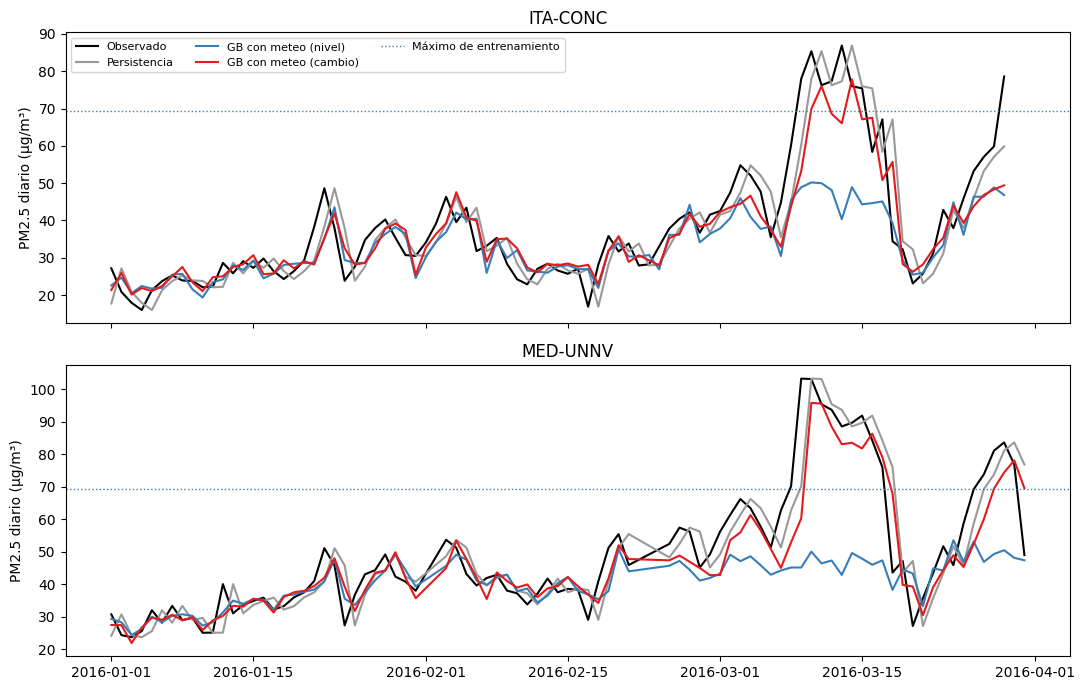

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for ax, station in zip(axes, BAENA_PM25_TO_METEO):
    mask = baena_test['station_id'] == station
    dates = baena_test.loc[mask, 'target_date']
    ax.plot(dates, baena_test.loc[mask, TARGET], color='black', label='Observado')
    ax.plot(dates, replica['persistencia'][mask], color='#999999', label='Persistencia')
    ax.plot(dates, replica['GB con meteo'][mask], color='#377eb8', label='GB con meteo (nivel)')
    ax.plot(dates, replica['GB con meteo (cambio)'][mask], color='#e41a1c', label='GB con meteo (cambio)')
    ax.axhline(baena_train[TARGET].max(), color='#377eb8', linestyle=':', linewidth=1, label='Máximo de entrenamiento')
    ax.set(ylabel='PM2.5 diario (µg/m³)', title=station)
axes[0].legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

**Con su mismo diseño, el modelo principal (que predice el nivel) es peor que la persistencia.** Su r² es de 0,72 en ITA-CONC y 0,53 en MED-UNNV, frente a 0,80 y 0,81 de la persistencia y 0,81 y 0,86 de Baena-Salazar et al. El problema está en 22 de los 175 días de prueba, que superan el máximo del entrenamiento. Un modelo de árboles predice promedios de los valores que vio al entrenar, así que nunca pronostica más de lo observado: aquí nunca pasó de 53,9 µg/m³. En esos 22 días su error medio es de 36 µg/m³, frente a 8 de la persistencia. En el resto de días es mejor que la persistencia (5,1 frente a 5,8 µg/m³), lo mismo que en 2022–2025.

**Si el modelo predice el cambio respecto a hoy**, la predicción parte del nivel actual y sí puede superar el rango de entrenamiento. Con esa variante el modelo con meteorología alcanza un r² de 0,80 en ITA-CONC y 0,82 en MED-UNNV, y un MAPE de 14,2 % y 11,5 %. Queda a la par de la red de Baena-Salazar et al. en r² (0,81 y 0,86) y con menor error porcentual (18,5 % y 12,4 %), y supera levemente a la persistencia. Esta variante se probó después de ver el resultado de 2016, por lo que es una explicación del fallo y no una evaluación independiente. En 2022–2025, donde no hubo niveles fuera de rango, predecir el cambio da un MAE algo mayor (2,79 frente a 2,74 µg/m³), y en la validación 2019–2021 ambas formulaciones empatan (3,18).

Tres conclusiones para la discusión:

1. La persistencia no fue comparada en el estudio local y, en su propio periodo de validación, iguala casi por completo a la red neuronal. Superarla es la verdadera prueba de un pronóstico diario.
2. Un modelo de árboles que predice el nivel falla justo en episodios sin precedentes, que son los que más importan. Si se espera que ocurran, conviene predecir el cambio o combinar ambas formulaciones.
3. Las comparaciones de r² entre estudios dependen del periodo: el mismo método de persistencia tiene r² de 0,80 en este trimestre y de 0,56 en 2022–2025 (sección 5).

Limitaciones de la réplica: solo dos de las tres estaciones, sin altura de capa de mezcla ni radiación (que sí usó la red), y la definición exacta de sus métricas no está documentada.

### 12.1 ¿Conviene predecir el cambio también en 2022–2025?

La réplica sugiere que predecir el cambio respecto a hoy protege frente a episodios sin precedentes. Aquí se comprueba, con el mismo origen móvil y la meteorología, si esa variante mejora en los días que importan de 2022–2025: los días en prevención y los inicios de episodio a igual presupuesto de avisos. La diferencia de MAE se estima con el mismo bootstrap por bloques de 14 días de la sección 7.1.

In [18]:
def gradient_boosting_change(columns):
    def fit_predict(train, test):
        model = HistGradientBoostingRegressor(**GB_PARAMS).fit(train[columns], train[TARGET] - train['pm25_mean'])
        return test['pm25_mean'].to_numpy() + model.predict(test[columns])
    return fit_predict


level_change = pd.DataFrame({
    'nivel': predictions['GB con meteo'],
    'cambio': rolling_origin_predictions(supervised, PREDICTED_YEARS, gradient_boosting_change(FEATURES_CON_METEO)),
})
in_test = evaluated['year'] >= TEST_YEARS[0]
lc_error = level_change.sub(evaluated[TARGET], axis=0)
lc_event = in_test & (evaluated[TARGET] >= PREVENTION_THRESHOLD)

rows = {}
for model in level_change:
    starts = 0
    for year in TEST_YEARS:
        calibration, mask = evaluated['year'] < year, evaluated['year'] == year
        threshold = threshold_for_budget(evaluated.loc[calibration, TARGET], level_change.loc[calibration, model])
        starts += warning_metrics(evaluated.loc[mask, TARGET], level_change.loc[mask, model],
                                  evaluated.loc[mask, 'inicio_episodio'], threshold)['inicios_avisados']
    rows[model] = {
        'MAE validación 2019–2021': lc_error.loc[~in_test, model].abs().mean(),
        'MAE 2022–2025': lc_error.loc[in_test, model].abs().mean(),
        'MAE días en prevención': lc_error.loc[lc_event, model].abs().mean(),
        'sesgo en días en prevención': lc_error.loc[lc_event, model].mean(),
        'inicios avisados (de 123)': starts,
    }
display(pd.DataFrame(rows).T.round(2))

gap = (lc_error.loc[in_test, 'cambio'].abs() - lc_error.loc[in_test, 'nivel'].abs()).to_frame('todos los días')
gap['días en prevención'] = gap['todos los días'].where(lc_event[in_test])
block = ((evaluated.loc[in_test, 'date'] - evaluated.loc[in_test, 'date'].min()).dt.days // 14).to_numpy()
block_sums, block_counts = gap.groupby(block).sum(), gap.groupby(block).count()
rng = np.random.default_rng(0)
draws = []
for _ in range(5000):
    sample = rng.integers(0, len(block_sums), len(block_sums))
    draws.append(block_sums.iloc[sample].sum() / block_counts.iloc[sample].sum())
draws = pd.DataFrame(draws)
display(pd.DataFrame({
    'cambio − nivel (MAE)': gap.mean(),
    'IC95_inferior': draws.quantile(0.025),
    'IC95_superior': draws.quantile(0.975),
}).round(3))

above_train = sum(
    int((evaluated.loc[evaluated['year'] == year, TARGET] > supervised.loc[supervised['year'] < year, TARGET].max()).sum())
    for year in TEST_YEARS
)
print('Máximo del target antes de 2022:', round(supervised.loc[supervised['year'] < TEST_YEARS[0], TARGET].max(), 1), 'µg/m³')
print('Máximo del target en 2022–2025:', round(evaluated.loc[in_test, TARGET].max(), 1), 'µg/m³')
print('Días de prueba por encima del máximo de su entrenamiento:', above_train)

,MAE validación 2019–2021,MAE 2022–2025,MAE días en prevención,sesgo en días en prevención,inicios avisados (de 123)
nivel,3.18,2.74,6.56,-5.46,30.0
cambio,3.18,2.79,6.57,-5.31,25.0


,cambio − nivel (MAE),IC95_inferior,IC95_superior
todos los días,0.047,0.024,0.070
días en prevención,0.012,-0.248,0.363


Máximo del target antes de 2022: 73.7 µg/m³
Máximo del target en 2022–2025: 59.5 µg/m³
Días de prueba por encima del máximo de su entrenamiento: 0


**En 2022–2025 predecir el cambio no ayuda.** En los días en prevención los dos modelos empatan (MAE de 6,56 y 6,57 µg/m³; el intervalo de la diferencia incluye el cero) y ambos subestiman los picos en más de 5 µg/m³. En todos los días el modelo de nivel es mejor (diferencia de 0,047 µg/m³, con un intervalo que excluye el cero) y, a igual presupuesto, anticipa 30 inicios frente a 25. La razón es que ningún día de prueba superó el máximo de su entrenamiento: los episodios de 2019–2020 (hasta 73,7 µg/m³) ya habían enseñado al modelo niveles más altos que todos los de 2022–2025 (hasta 59,5).

**Decisión (2026-10-18):** el modelo principal sigue prediciendo el nivel. Se eligió antes de ver la prueba y no pierde en los días críticos. El fallo de 2016 se reporta en la discusión como limitación: un modelo de árboles que predice el nivel subestima los episodios más fuertes que los del entrenamiento. La solución propuesta es predecir el cambio.

## 13. Siguientes pasos

1. Sensibilidad (opcional): exclusión de BEL-FEVE y MED-SCRI, y alternativas para los huecos meteorológicos.
2. Redacción del paper y de la presentación con las cifras de este notebook y las figuras de la sección 14.

## 14. Figuras del paper

Las figuras de resultados del paper se exportan a `paper/figuras/` en PDF, al ancho de una columna IEEE, con el mismo estilo que las del notebook `01_eda_pm25.ipynb`. Usan objetos ya calculados (`importance_pct`, `GROUPS`, `baena_test`, `baena_train` y `replica`). Los diagramas de flujo no salen de aquí: son TikZ y están en `paper/figuras/diagramas/`.

In [19]:
FIGURES_DIR = PROJECT_ROOT / 'paper' / 'figuras'
FIG_STYLE = {
    'font.size': 8,
    'axes.titlesize': 8.5,
    'axes.labelsize': 8,
    'xtick.labelsize': 7.5,
    'ytick.labelsize': 7.5,
    'legend.fontsize': 7,
    'figure.dpi': 120,
}
LABELS = {
    'pm25_mean': 'Media de hoy', 'pm25_evening_mean': 'Media de hoy, 18–23 h', 'pm25_max': 'Máximo de hoy',
    'pm25_roll3_mean': 'Media de 3 días', 'pm25_roll7_mean': 'Media de 7 días', 'pm25_roll7_std': 'Desv. de 7 días',
    'pm25_diff1': 'Cambio hoy − ayer', 'target_month': 'Mes', 'target_day_of_week': 'Día de la semana',
    'estación': 'Estación', 't': 'Temperatura', 'h': 'Humedad', 'pr': 'Presión', 'p': 'Lluvia',
    'p_sum3': 'Lluvia de 3 días', 'vv': 'Viento medio', 'vv_max': 'Viento máximo',
    **{f'pm25_lag{k}': f'Rezago de {k} día' + ('s' if k > 1 else '') for k in range(1, 7)},
}
GROUP_COLORS = {
    'PM2.5 de hoy': '#377eb8', 'Rezagos y ventanas': '#984ea3', 'Calendario': '#ff7f00',
    'Meteorología': '#4daf4a', 'Estación': '#999999',
}
group_of = {column: group for group, columns in GROUPS.items() for column in columns}

with plt.rc_context(FIG_STYLE):
    # Importancia SHAP de las 12 variables con más peso, coloreadas por grupo.
    top = importance_pct.index[:12][::-1]
    fig, ax = plt.subplots(figsize=(3.5, 3.6))
    ax.barh([LABELS[c] for c in top], importance_pct[top], color=[GROUP_COLORS[group_of[c]] for c in top])
    handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in GROUP_COLORS.values()]
    ax.legend(handles, [f'{g} ({importance_pct[GROUPS[g]].sum():.1f} %)' for g in GROUP_COLORS],
              loc='upper center', bbox_to_anchor=(0.35, -0.16), ncol=2, fontsize=6.5, frameon=False)
    ax.set(xlabel='Importancia SHAP (% del total)', title='Peso de cada variable, GB con meteorología, 2022–2025')
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / 'importancia_shap.pdf', bbox_inches='tight')
    plt.close(fig)

    # Réplica de Baena-Salazar et al.: observado y pronósticos en enero–marzo de 2016.
    fig, axes = plt.subplots(2, 1, figsize=(3.5, 4.3), sharex=True)
    for ax, station in zip(axes, BAENA_PM25_TO_METEO):
        mask = baena_test['station_id'] == station
        dates = baena_test.loc[mask, 'target_date']
        ax.plot(dates, baena_test.loc[mask, TARGET], color='black', linewidth=1, label='Observado')
        ax.plot(dates, replica['persistencia'][mask], color='#999999', linewidth=0.8, label='Persistencia')
        ax.plot(dates, replica['GB con meteo'][mask], color='#377eb8', linewidth=0.8, label='GB (nivel)')
        ax.plot(dates, replica['GB con meteo (cambio)'][mask], color='#e41a1c', linewidth=0.8, label='GB (cambio)')
        ax.axhline(baena_train[TARGET].max(), color='#377eb8', linestyle=':', linewidth=0.8, label='Máximo de entrenamiento')
        ax.set(ylabel='PM2.5 (µg/m³)', title=station)
    months = ['ene', 'feb', 'mar', 'abr']
    axes[1].xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator(bymonthday=[1, 15]))
    axes[1].xaxis.set_major_formatter(plt.FuncFormatter(
        lambda x, _: f'{plt.matplotlib.dates.num2date(x).day} {months[plt.matplotlib.dates.num2date(x).month - 1]}'))
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    fig.legend(*axes[0].get_legend_handles_labels(), loc='upper center', ncol=3, fontsize=6, frameon=False)
    fig.savefig(FIGURES_DIR / 'replica_baena.pdf', bbox_inches='tight')
    plt.close(fig)

print('Figuras exportadas a', FIGURES_DIR.relative_to(PROJECT_ROOT))

Figuras exportadas a paper/figuras
